# Part 1 — reproduction of the Python-module experiments

Reproduces the root Python-module implementation: training-only embedding standardization, supervised baseline, K-Means/GMM pseudo-labeling, weighted classifiers, cluster features, random pseudo-label control, threshold tuning, RBF SVM, cluster-count controls, and the nonempty Kaggle fallback. The historical notebook-only workflow is packaged separately; its results must not be conflated with these experiments.

This notebook embeds the source implementation; it does not import project-specific Python modules. Standard-library and third-party imports are sufficient. Run cells in order from a fresh kernel. Default verification mode reads explicitly labeled historical references without fitting. Set `RUN_FULL=True` for fresh computation. All generated outputs are isolated under `part2/notebook_reproduction/`.


## Imports, paths, execution mode and preservation checks


In [1]:
from pathlib import Path
import os
import hashlib
import json
# Configure numerical thread limits before NumPy/scikit-learn are imported.
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
ROOT = Path.cwd().resolve()
if ROOT.name == 'part2':
    ROOT = ROOT.parent
if not all((ROOT / name).is_dir() for name in ('part1-data', 'part2-data')):
    raise FileNotFoundError('Start the notebook from the repository root or its part2/ directory.')
REPRO_ROOT = ROOT / 'part2' / 'notebook_reproduction'
RUN_FULL = False  # Change to True for fresh complete training; verify mode never fits models.
# Original artifacts are read-only references. Every newly generated artifact stays below REPRO_ROOT.
def protected_hashes():
    paths = []
    for directory in ('part1-data', 'part2-data', 'outputs', 'part1-results', 'part2-results',
                      'part2/outputs', 'part2/calibration_outputs', 'writeup'):
        if (ROOT / directory).exists():
            paths.extend(p for p in (ROOT / directory).rglob('*') if p.is_file())
    paths.extend(ROOT.glob('*.py'))
    paths.extend((ROOT / 'part2').glob('*.py'))
    return {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
ORIGINAL_HASHES = protected_hashes()
print('Mode:', 'full fresh reproduction' if RUN_FULL else 'verification only — no model fitting')


Mode: verification only — no model fitting


In [2]:
DATA_DIR = ROOT / 'part1-data'
OUTPUT_DIR = REPRO_ROOT / 'part1'
TRAIN_PATH = DATA_DIR / 'part1_train.csv'
VAL_PATH = DATA_DIR / 'part1_val.csv'
TEST_PATH = DATA_DIR / 'part1_test.csv'
RANDOM_STATE = 42
LABELS = ['Safety', 'Funding', 'Efficacy', 'Recruitment', 'Other']
FEATURES = [f'emb_{i}' for i in range(150)]
K = 8
SMOOTHING = 5.0
LOW_CONFIDENCE = 0.2
HIGH_CONFIDENCE = 0.8
MIN_LABELED_CLUSTER = 5
PSEUDO_WEIGHT = 0.3
SUBMISSION_THRESHOLDS = [0.20, 0.20, 0.20, 0.40, 0.40]


## Dataset preparation

All 1,171 training embeddings fit the scaler; only 157 visible reason-label rows supervise the initial classifier. Validation embeddings are transformed without fitting. Masked labels stay masked until pseudo-label generation.


In [3]:
from dataclasses import dataclass
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler


### `Dataset`

Implementation copied from `data_utils.py`.


In [4]:
@dataclass
class Dataset:
    train: pd.DataFrame
    val: pd.DataFrame
    scaler: StandardScaler
    X_train: np.ndarray
    X_val: np.ndarray
    X_labeled: np.ndarray
    X_unlabeled: np.ndarray
    y_labeled: np.ndarray
    y_val: np.ndarray
    labeled_mask: np.ndarray
    unlabeled_mask: np.ndarray


### `load_data`

Implementation copied from `data_utils.py`.


In [5]:
def load_data():
    train = pd.read_csv(TRAIN_PATH)
    val = pd.read_csv(VAL_PATH)
    labeled_mask = (train[LABELS] != -100).all(axis=1).to_numpy()
    unlabeled_mask = (train[LABELS] == -100).all(axis=1).to_numpy()
    if not np.all(labeled_mask | unlabeled_mask):
        raise ValueError("Some training rows have partially missing labels.")
    scaler = StandardScaler()
    X_train = scaler.fit_transform(train[FEATURES])
    X_val = scaler.transform(val[FEATURES])
    return Dataset(
        train, val, scaler, X_train, X_val,
        X_train[labeled_mask], X_train[unlabeled_mask],
        train.loc[labeled_mask, LABELS].to_numpy(dtype=int),
        val[LABELS].to_numpy(dtype=int), labeled_mask, unlabeled_mask,
    )


### `load_test`

Implementation copied from `data_utils.py`.


In [6]:
def load_test(scaler):
    test = pd.read_csv(TEST_PATH)
    return test, scaler.transform(test[FEATURES])


In [7]:
data = load_data()
print("Labeled:", len(data.X_labeled), "Unlabeled:", len(data.X_unlabeled))
display(data.train[LABELS].value_counts().rename("rows").to_frame())


Labeled: 157 Unlabeled: 1014


rows
Safety Funding Efficacy Recruitment Other      
-100   -100    -100     -100        -100   1014
 0      0       0        1           0       91
                         0           1       19
                1        0           0       17
 1      0       0        0           0       16
 0      0       0        1           1        6
        1       0        1           0        4
                         0           0        4

## Classifiers, multilabel metrics and thresholds

Each reason has a binary balanced logistic classifier. Report sample-wise F1, macro F1 and per-reason F1. The original threshold search uses validation data; these scores therefore reflect model selection.


In [8]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.svm import SVC


### `train_ovr`

Implementation copied from `models.py`.


In [9]:
def train_ovr(X, y, sample_weight=None):
    models = []
    for j in range(y.shape[1]):
        model = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
        model.fit(X, y[:, j], sample_weight=sample_weight)
        models.append(model)
    return models


### `train_rbf_svm`

Implementation copied from `models.py`.


In [10]:
def train_rbf_svm(X, y):
    models = []
    for j in range(y.shape[1]):
        model = SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced", probability=True, random_state=RANDOM_STATE)
        model.fit(X, y[:, j])
        models.append(model)
    return models


### `predict_probabilities`

Implementation copied from `models.py`.


In [11]:
def predict_probabilities(models, X):
    return np.column_stack([model.predict_proba(X)[:, 1] for model in models])


### `predict_labels`

Implementation copied from `models.py`.


In [12]:
def predict_labels(probabilities, thresholds=0.5, ensure_one=False):
    predictions = (probabilities >= np.asarray(thresholds)).astype(int)
    if ensure_one:
        empty = np.flatnonzero(predictions.sum(axis=1) == 0)
        predictions[empty, np.argmax(probabilities[empty], axis=1)] = 1
    return predictions


### `evaluate_predictions`

Implementation copied from `models.py`.


In [13]:
def evaluate_predictions(name, y, predictions):
    result = {
        "Experiment": name,
        "Sample F1": f1_score(y, predictions, average="samples", zero_division=0),
        "Macro F1": f1_score(y, predictions, average="macro", zero_division=0),
    }
    for j, reason in enumerate(LABELS):
        result[reason] = f1_score(y[:, j], predictions[:, j], zero_division=0)
    return result


### `evaluate`

Implementation copied from `models.py`.


In [14]:
def evaluate(name, models, X, y, thresholds=0.5, ensure_one=False):
    probs = predict_probabilities(models, X)
    return evaluate_predictions(name, y, predict_labels(probs, thresholds, ensure_one))


### `tune_thresholds`

Implementation copied from `models.py`.


In [15]:
def tune_thresholds(probs, y, candidates=None):
    if candidates is None:
        candidates = np.arange(0.20, 0.81, 0.05)
    thresholds = []
    per_label_scores = []
    for j in range(y.shape[1]):
        scores = [f1_score(y[:, j], probs[:, j] >= t, zero_division=0) for t in candidates]
        idx = int(np.argmax(scores))
        thresholds.append(float(candidates[idx]))
        per_label_scores.append(float(scores[idx]))
    return np.asarray(thresholds), per_label_scores


## Clustering and weighted pseudo-label augmentation

K-Means uses K=8 and seed 42. Smoothed cluster rates, support and confidence criteria are unchanged. Pseudo-labeled rows have weight 0.3; observed labels have weight 1. The GMM and per-label variants are reproduced exactly.


In [16]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture


### `estimate_cluster_labels`

Implementation copied from `pseudo_labeling.py`.


In [17]:
def estimate_cluster_labels(labeled_clusters, y_labeled, K, smoothing=SMOOTHING):
    prior = y_labeled.mean(axis=0)
    cluster_probs = np.zeros((K, len(LABELS)))
    cluster_counts = np.zeros(K, dtype=int)
    for k in range(K):
        mask = labeled_clusters == k
        count = int(mask.sum())
        cluster_counts[k] = count
        positive_counts = y_labeled[mask].sum(axis=0)
        cluster_probs[k] = (positive_counts + smoothing * prior) / (count + smoothing)
    return cluster_probs, cluster_counts


### `estimate_soft_cluster_labels`

Implementation copied from `pseudo_labeling.py`.


In [18]:
def estimate_soft_cluster_labels(memberships, y, smoothing=SMOOTHING):
    prior = y.mean(axis=0)
    counts = memberships.sum(axis=0)
    positives = memberships.T @ y
    probabilities = (positives + smoothing * prior) / (counts[:, None] + smoothing)
    return probabilities, counts


### `augment_and_train`

Implementation copied from `pseudo_labeling.py`.


In [19]:
def augment_and_train(X_labeled, y_labeled, pseudo_X, pseudo_y, weight=PSEUDO_WEIGHT):
    X_aug = np.vstack([X_labeled, pseudo_X])
    y_aug = np.vstack([y_labeled, pseudo_y])
    weights = np.concatenate([np.ones(len(y_labeled)), np.full(len(pseudo_y), weight)])
    return train_ovr(X_aug, y_aug, sample_weight=weights)


### `fit_kmeans_pseudo`

Implementation copied from `pseudo_labeling.py`.


In [20]:
def fit_kmeans_pseudo(data, K=8):
    km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
    cluster_ids = km.fit_predict(data.X_train)
    labeled_clusters = cluster_ids[data.labeled_mask]
    unlabeled_clusters = cluster_ids[data.unlabeled_mask]
    cluster_probs, cluster_counts = estimate_cluster_labels(labeled_clusters, data.y_labeled, K)
    pseudo_probs = cluster_probs[unlabeled_clusters]
    confident = ((pseudo_probs <= LOW_CONFIDENCE) | (pseudo_probs >= HIGH_CONFIDENCE)).all(axis=1)
    confident &= cluster_counts[unlabeled_clusters] >= MIN_LABELED_CLUSTER
    pseudo_y = (pseudo_probs[confident] >= HIGH_CONFIDENCE).astype(int)
    models = augment_and_train(data.X_labeled, data.y_labeled, data.X_unlabeled[confident], pseudo_y)
    return {
        "models": models, "clusterer": km, "cluster_probs": cluster_probs,
        "cluster_counts": cluster_counts, "unlabeled_clusters": unlabeled_clusters,
        "pseudo_probs": pseudo_probs, "confident": confident, "pseudo_y": pseudo_y,
    }


### `fit_gmm_pseudo`

Implementation copied from `pseudo_labeling.py`.


In [21]:
def fit_gmm_pseudo(data):
    gmm = GaussianMixture(n_components=8, covariance_type="diag", reg_covar=1e-4, random_state=RANDOM_STATE, n_init=3)
    gmm.fit(data.X_train)
    memberships = gmm.predict_proba(data.X_train)
    labeled_memberships = memberships[data.labeled_mask]
    unlabeled_memberships = memberships[data.unlabeled_mask]
    cluster_probs, counts = estimate_soft_cluster_labels(labeled_memberships, data.y_labeled)
    pseudo_probs = unlabeled_memberships @ cluster_probs
    confident = ((pseudo_probs <= LOW_CONFIDENCE) | (pseudo_probs >= HIGH_CONFIDENCE)).all(axis=1)
    support = unlabeled_memberships @ counts
    confident &= support >= MIN_LABELED_CLUSTER
    pseudo_y = (pseudo_probs[confident] >= HIGH_CONFIDENCE).astype(int)
    models = augment_and_train(data.X_labeled, data.y_labeled, data.X_unlabeled[confident], pseudo_y)
    return {"models": models, "clusterer": gmm, "confident": confident, "pseudo_y": pseudo_y}


### `fit_per_label_kmeans`

Implementation copied from `pseudo_labeling.py`.


In [22]:
def fit_per_label_kmeans(data, kmeans_result):
    from sklearn.linear_model import LogisticRegression
    pseudo_probs = kmeans_result["pseudo_probs"]
    valid = kmeans_result["cluster_counts"][kmeans_result["unlabeled_clusters"]] >= MIN_LABELED_CLUSTER
    models, counts = [], {}
    for j, reason in enumerate(LABELS):
        probs = pseudo_probs[:, j]
        confident = ((probs <= LOW_CONFIDENCE) | (probs >= HIGH_CONFIDENCE)) & valid
        pseudo_y = (probs[confident] >= HIGH_CONFIDENCE).astype(int)
        X_aug = np.vstack([data.X_labeled, data.X_unlabeled[confident]])
        y_aug = np.concatenate([data.y_labeled[:, j], pseudo_y])
        weights = np.concatenate([np.ones(len(data.y_labeled)), np.full(len(pseudo_y), PSEUDO_WEIGHT)])
        model = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
        model.fit(X_aug, y_aug, sample_weight=weights)
        models.append(model)
        counts[reason] = {"Total": len(pseudo_y), "Positive": int(pseudo_y.sum()), "Negative": int((pseudo_y == 0).sum())}
    return models, counts


## Complete existing experiment suite

Full mode executes A–H and the existing K=(4,6,8,10,12,16) comparison. This preserves the original grid rather than starting a new search. Verify mode does not fit classifiers.


In [23]:
import argparse
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler


### `run_experiments`

Implementation copied from `experiments.py`.


In [24]:
def run_experiments(data, include_svm=True):
    results = []
    baseline = train_ovr(data.X_labeled, data.y_labeled)
    results.append(evaluate("A: Supervised baseline", baseline, data.X_val, data.y_val))

    km = fit_kmeans_pseudo(data, K=K)
    print("K-Means cluster probabilities:\n", pd.DataFrame(km["cluster_probs"], columns=LABELS))
    print("Labeled examples per cluster:", km["cluster_counts"])
    print("K-Means pseudo-labeled trials:", len(km["pseudo_y"]))
    results.append(evaluate("B: K-Means + LR", km["models"], data.X_val, data.y_val))

    gmm = fit_gmm_pseudo(data)
    print("GMM pseudo-labeled trials:", len(gmm["pseudo_y"]))
    results.append(evaluate("C: GMM + LR", gmm["models"], data.X_val, data.y_val))
    print("K-Means pseudo-label counts:\n", pd.DataFrame(km["pseudo_y"], columns=LABELS).sum())

    per_label_models, counts = fit_per_label_kmeans(data, km)
    print("Per-label pseudo-label counts:\n", pd.DataFrame(counts).T)
    results.append(evaluate("D: Per-label K-Means + LR", per_label_models, data.X_val, data.y_val))

    print("\nPredicted positive counts at threshold 0.5:")
    for name, models in [("Baseline", baseline), ("K-Means", km["models"]), ("GMM", gmm["models"]), ("Per-label", per_label_models)]:
        preds = predict_labels(predict_probabilities(models, data.X_val))
        print(name, dict(zip(LABELS, preds.sum(axis=0))))
    print("Actual:", dict(zip(LABELS, data.y_val.sum(axis=0))))

    dist_train = km["clusterer"].transform(data.X_labeled)
    dist_val = km["clusterer"].transform(data.X_val)
    distance_scaler = StandardScaler()
    X_labeled_ext = np.hstack([data.X_labeled, distance_scaler.fit_transform(dist_train)])
    X_val_ext = np.hstack([data.X_val, distance_scaler.transform(dist_val)])
    feature_models = train_ovr(X_labeled_ext, data.y_labeled)
    results.append(evaluate("E: K-Means Features + LR", feature_models, X_val_ext, data.y_val))

    rng = np.random.default_rng(RANDOM_STATE)
    n_pseudo = len(km["pseudo_y"])
    indices = rng.choice(len(data.X_unlabeled), size=n_pseudo, replace=False)
    # Preserve original Experiment F's Recruitment-only pseudo-label pattern.
    random_y = np.tile(np.array([0, 0, 0, 1, 0]), (n_pseudo, 1))
    random_models = augment_and_train(data.X_labeled, data.y_labeled, data.X_unlabeled[indices], random_y)
    results.append(evaluate("F: Random Pseudo-label Control", random_models, data.X_val, data.y_val))

    val_probs = predict_probabilities(km["models"], data.X_val)
    best_thresholds, per_label_f1 = tune_thresholds(val_probs, data.y_val)
    print("\nTuned thresholds:", dict(zip(LABELS, np.round(best_thresholds, 2))))
    print("Per-label tuned F1:", dict(zip(LABELS, np.round(per_label_f1, 3))))
    results.append(evaluate_predictions("G: K-Means + Tuned Thresholds", data.y_val, predict_labels(val_probs, best_thresholds)))
    # Kaggle submission uses a fallback for empty predictions; report it separately.
    results.append(evaluate_predictions("G: Tuned + Nonempty Fallback", data.y_val, predict_labels(val_probs, SUBMISSION_THRESHOLDS, ensure_one=True)))

    if include_svm:
        svm = train_rbf_svm(data.X_labeled, data.y_labeled)
        results.append(evaluate("H: RBF SVM", svm, data.X_val, data.y_val))

    comparison = pd.DataFrame(results).sort_values("Sample F1", ascending=False)
    OUTPUT_DIR.mkdir(exist_ok=True)
    comparison.to_csv(OUTPUT_DIR / "experiment_results.csv", index=False)
    print("\nExperiment results:\n", comparison.round(4).to_string(index=False))
    return {"baseline": baseline, "kmeans": km, "gmm": gmm, "results": comparison, "thresholds": best_thresholds}


### `compare_cluster_counts`

Implementation copied from `experiments.py`.


In [25]:
def compare_cluster_counts(data, ks=(4, 6, 8, 10, 12, 16)):
    rows = []
    for k in ks:
        result = fit_kmeans_pseudo(data, K=k)
        models = result["models"]
        for threshold_name, thresholds in [("default", 0.5), ("previously tuned", SUBMISSION_THRESHOLDS)]:
            metrics = evaluate(f"K={k}", models, data.X_val, data.y_val, thresholds=thresholds)
            rows.append({"K": k, "Thresholds": threshold_name, "Pseudo-labeled": len(result["pseudo_y"]), "Sample F1": metrics["Sample F1"], "Macro F1": metrics["Macro F1"]})
    table = pd.DataFrame(rows)
    OUTPUT_DIR.mkdir(exist_ok=True)
    table.to_csv(OUTPUT_DIR / "cluster_count_comparison.csv", index=False)
    print("\nK-Means cluster count comparison:\n", table.round(4).to_string(index=False))
    return table


In [26]:
import argparse
import numpy as np
import pandas as pd


### `make_submission`

Implementation copied from `submission.py`.


In [27]:
def make_submission(test, probabilities, thresholds=SUBMISSION_THRESHOLDS, ensure_one=True):
    preds = predict_labels(probabilities, thresholds, ensure_one=ensure_one)
    predicted_labels = [" ".join(label for label, positive in zip(LABELS, row) if positive) for row in preds]
    submission = pd.DataFrame({"ID": test["ID"], "Predicted": predicted_labels})
    assert submission["ID"].notna().all() and submission["ID"].is_unique
    assert submission["Predicted"].notna().all()
    assert (submission["Predicted"].str.len() > 0).all(), "Kaggle rejects empty predictions."
    assert all(set(s.split()).issubset(set(LABELS)) for s in submission["Predicted"])
    return submission, preds


In [28]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if RUN_FULL:
    experiment_run = run_experiments(data, include_svm=True)
    cluster_results = compare_cluster_counts(data)
    # Reuse the identically configured deterministic K=8 fit from the experiment suite.
    selected_models = experiment_run['kmeans']['models']
    test, X_test = load_test(data.scaler)
    test_probs = predict_probabilities(selected_models, X_test)
    submission, _ = make_submission(test, test_probs, SUBMISSION_THRESHOLDS, ensure_one=True)
    submission.to_csv(OUTPUT_DIR / 'part1_submission.csv', index=False)
    print('Fresh submission saved:', OUTPUT_DIR / 'part1_submission.csv')
else:
    print('Skipped fresh A–H training, K sweep, and submission fitting in verification mode.')


Skipped fresh A–H training, K sweep, and submission fitting in verification mode.


## Historical artifact verification and comparison

The next cell is explicitly read-only verification. It is not fresh experimental output. Full mode additionally compares recomputed metrics and the submission with the originals.


In [29]:
reference_path = ROOT / 'outputs' / 'experiment_results.csv'
k_reference_path = ROOT / 'outputs' / 'cluster_count_comparison.csv'
expected = pd.read_csv(reference_path) if reference_path.exists() else experiment_run['results']
expected_k = pd.read_csv(k_reference_path) if k_reference_path.exists() else cluster_results
display(expected)
display(expected_k)
if RUN_FULL:
    fresh = experiment_run['results'].set_index('Experiment').sort_index()
    reference = expected.set_index('Experiment').sort_index()
    assert list(fresh.index) == list(reference.index)
    assert np.allclose(fresh.select_dtypes('number'), reference.select_dtypes('number'), atol=1e-6)
    original_path = ROOT / 'outputs' / 'part1_submission.csv'
    if original_path.exists():
        assert submission.equals(pd.read_csv(original_path))


,Experiment,Sample F1,Macro F1,Safety,Funding,Efficacy,Recruitment,Other
0,G: K-Means + Tuned Thresholds,0.882479,0.786734,0.900000,0.666667,0.740741,0.989899,0.636364
1,G: Tuned + Nonempty Fallback,0.882479,0.777280,0.900000,0.666667,0.740741,0.970297,0.608696
2,B: K-Means + LR,0.865385,0.769697,0.888889,0.666667,0.666667,0.989899,0.636364
3,A: Supervised baseline,0.848291,0.745282,0.823529,0.666667,0.720000,0.989899,0.526316
4,E: K-Means Features + LR,0.848291,0.745282,0.823529,0.666667,0.720000,0.989899,0.526316
5,C: GMM + LR,0.826923,0.683167,0.823529,0.400000,0.750000,0.942308,0.500000
6,H: RBF SVM,0.803419,0.673647,0.800000,0.400000,0.600000,0.980000,0.588235
7,D: Per-label K-Means + LR,0.794872,0.634728,0.800000,0.400000,0.695652,0.970297,0.307692
8,F: Random Pseudo-label Control,0.739316,0.529562,0.461538,0.400000,0.526316,0.884956,0.375000


,K,Thresholds,Pseudo-labeled,Sample F1,Macro F1
0,4,default,550,0.818376,0.657634
1,4,previously tuned,550,0.861111,0.755541
2,6,default,377,0.844017,0.699734
3,6,previously tuned,377,0.880342,0.781443
4,8,default,285,0.865385,0.769697
5,8,previously tuned,285,0.882479,0.786734
6,10,default,402,0.814103,0.662863
7,10,previously tuned,402,0.856838,0.715014
8,12,default,494,0.818376,0.666994
9,12,previously tuned,494,0.856838,0.731086


## Existing experiment results as a figure

This is a visualization of the existing measured table, not a new experiment.


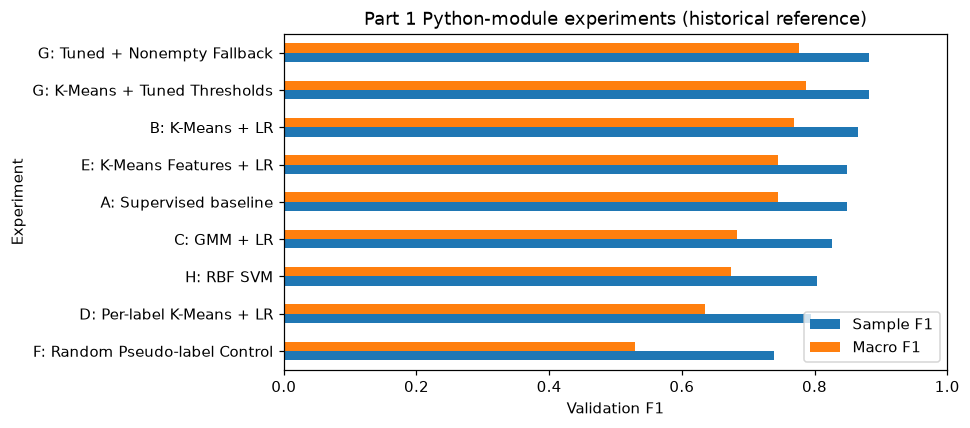

In [30]:
import matplotlib.pyplot as plt
figure, ax = plt.subplots(figsize=(9, 4))
(experiment_run['results'] if RUN_FULL else expected).sort_values('Sample F1').plot.barh(x='Experiment', y=['Sample F1', 'Macro F1'], ax=ax)
ax.set(xlim=(0, 1), xlabel='Validation F1', title='Part 1 Python-module experiments (' + ('fresh' if RUN_FULL else 'historical reference') + ')')
figure.tight_layout()
figure_dir = OUTPUT_DIR / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)
figure.savefig(figure_dir / 'experiment_f1.png', dpi=140)
plt.show()


## Findings and limits

These are validation scores, not Kaggle leaderboard scores. The module report favors K=8 K-Means pseudo-label augmentation with reason-specific thresholds and a nonempty fallback. The separate historical workflow includes additional experiments and different settings. No hidden labels or external data are used.


In [31]:
after = protected_hashes()
assert all(after.get(path) == digest for path, digest in ORIGINAL_HASHES.items())
print('Existing source files, data, models, reports, predictions and submissions are unchanged.')


Existing source files, data, models, reports, predictions and submissions are unchanged.
